# DDS-8555 Assignment 7: Build and Evaluate Unsupervised Learning Models
**Nathan Weber** · National University · DDS-8555: Predictive Analysis · Dr. Alexander Watt

**How to run:** Runtime → Run all. Approve the Google Drive prompt. When the upload button appears, choose the Kaggle wine zip (only the first time). Figures and results are saved to Drive → DDS8555 → output.

| Rubric item | Where |
|---|---|
| Completes Conceptual Question (ISLP Ch. 12, Q1) | Part 1 |
| Completes Applied Question (ISLP Ch. 12, Q9, USArrests) | Part 2 |
| Conducts PCA (components covering at least 80% of the variance) | Part 3 |
| Conducts k-means for different values of k | Part 4 |
| Conducts hierarchical clustering | Part 5 |
| Investigates assumptions | Part 3 (PCA checks) and Part 6 (clustering checks) |
| Posts code to GitHub | This notebook (repo DDS8555) |

In [1]:
# ==============================================================================
# DDS-8555 Predictive Analysis | Assignment 7: Build & Evaluate Unsupervised Learning Models (Part 1 of 1)
# National University | Instructor: Dr. Alexander V. Watt | Author: Nathan Weber
# Notebook: DDS8555_ASGN7Part1of1_Unsupervised_NWeber.ipynb
# Paper:    WeberN_DDS8555-910002634_ASGN7Part1of1.docx  (the written report; code is not reproduced there)
# Version:  v1.1, 2026-11-02 (see the change log at the end of this cell)
# ------------------------------------------------------------------------------
# RUN:      Google Colab -> Runtime -> Run all (also runs locally with Python 3.10+).
#           Needs: numpy, pandas, matplotlib, scikit-learn, statsmodels, scipy, ISLP.
# INPUTS:   Kaggle 'Wine Dataset for Clustering' (harrywang/wine-dataset-for-clustering): the CSV
#           (or the zip) in Google Drive/MyDrive/DDS8555/wine. Textbook data come from the ISLP package.
#           https://www.kaggle.com/datasets/harrywang/wine-dataset-for-clustering
#           (the UCI Wine data without the cultivar label; original: Aeberhard & Forina, 1991,
#           https://doi.org/10.24432/C5PC7J)
# OUTPUTS:  Drive/MyDrive/DDS8555/output: A7_fig_kmeans_check.png, A7_fig_usarrests.png, A7_fig_pca.png, A7_fig_kchoice.png, A7_fig_dendrogram.png, A7_results.json
# ------------------------------------------------------------------------------
# QUESTION: Can 13 chemical measurements of 178 wines be summarized by a few principal components, and do the wines form natural groups? PCA to at least 80% of the variance, k-means for k = 2 to 8, and hierarchical clustering. Also ISLP Ch. 12 conceptual Q1 and applied Q9 (USArrests).
# TARGET:   None (unsupervised). The wine data carry no labels, so clusters are judged by internal
#           measures (silhouette, Calinski-Harabasz, Davies-Bouldin) and by agreement between methods.
# CLEANING: no rows dropped; all 13 measurements standardized to mean 0, SD 1 before PCA,
#           because they are on very different scales (proline is in the hundreds, hue near 1).
# VALIDATION:k chosen by silhouette with elbow and two other indices as checks; stability of
#           k-means checked across 20 random starts (adjusted Rand index); the choice of k is
#           re-made on 100 random 80% subsamples of the wines to show how firm it is.
# SEEDS:    random_state=42 for k-means and the stability check.
# DEPENDS ON: None. Independent of A2-A6.
# CHECKS:   input SHA-256 fingerprints, row counts, column names, and package versions
#           are printed below and at the end, so a re-run can be compared line by line.
# ------------------------------------------------------------------------------
# CHANGE LOG:
#   v1.0  2026-10-28  First version.
#   v1.1  2026-11-02  Added Horn's parallel analysis as a second check on the number of
#                     components; added a subsample check of how often each k wins on
#                     silhouette; added the data-provenance note; output list corrected.
# ==============================================================================

In [2]:
## ---- 0. Setup and imports ------------------------------------------------------
# ---- 0. Setup: runs in Google Colab (also runs locally) ----
import sys, os, glob, zipfile, json, time, warnings, hashlib, datetime
warnings.filterwarnings("ignore"); os.environ["PYTHONWARNINGS"] = "ignore"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive, files
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/DDS8555"
    !pip -q install --no-deps ISLP
else:
    BASE = os.environ.get("DDS8555_BASE", ".")
DATA_DIR = os.path.join(BASE, "wine")
OUT_DIR = os.path.join(BASE, "output")
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
pd.set_option("display.width", 120); pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 110
RESULTS = {}          # every number the paper uses is stored here and printed at the end
T0 = time.time()

def unzip_all(folder):
    """Extract every zip in the folder (and zips inside zips), once."""
    for _ in range(2):
        for z in glob.glob(os.path.join(folder, "*.zip")):
            with zipfile.ZipFile(z) as f:
                for name in f.namelist():
                    target = os.path.join(folder, os.path.basename(name))
                    if name.endswith("/") or os.path.exists(target):
                        continue
                    with f.open(name) as src, open(target, "wb") as dst:
                        dst.write(src.read())

def get_files(need):
    """Make sure every file in `need` is in DATA_DIR; in Colab, ask for an upload once if not."""
    unzip_all(DATA_DIR)
    if IN_COLAB and not all(os.path.exists(os.path.join(DATA_DIR, f)) for f in need):
        print("Choose the Kaggle download (the zip, or the CSV files):")
        for name, data in files.upload().items():
            open(os.path.join(DATA_DIR, name), "wb").write(data)
        unzip_all(DATA_DIR)
    missing = [f for f in need if not os.path.exists(os.path.join(DATA_DIR, f))]
    assert not missing, f"Missing files in {DATA_DIR}: {missing}  (found: {sorted(os.listdir(DATA_DIR))})"

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def fingerprint(names):
    fp = {f: sha256(os.path.join(DATA_DIR, f)) for f in names}
    print("Run started (UTC):", datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M"))
    for f, h in fp.items():
        print(f"SHA-256 {f:<28} {h}")
    return fp

def save_fig(name):
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, name), dpi=150); plt.show()

def download(path):
    if IN_COLAB:
        files.download(path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Part 1. Conceptual Question 1 (ISLP Chapter 12)
**(a) Prove (12.18).** For a cluster $C_k$ with $|C_k|$ observations and centroid $\bar x_{kj} = \frac{1}{|C_k|}\sum_{i \in C_k} x_{ij}$, the identity is

$$\frac{1}{|C_k|}\sum_{i,i' \in C_k}\sum_{j=1}^{p}(x_{ij}-x_{i'j})^2 = 2\sum_{i \in C_k}\sum_{j=1}^{p}(x_{ij}-\bar x_{kj})^2 .$$

*Proof (one variable j at a time, then sum over j).* Write $x_{ij}-x_{i'j} = (x_{ij}-\bar x_{kj}) - (x_{i'j}-\bar x_{kj}) = a_i - a_{i'}$, where $a_i = x_{ij}-\bar x_{kj}$ and $\sum_{i\in C_k} a_i = 0$ because the deviations from a mean sum to zero. Then

$$\sum_{i,i'}(a_i-a_{i'})^2 = \sum_{i,i'}a_i^2 + \sum_{i,i'}a_{i'}^2 - 2\sum_{i,i'}a_i a_{i'} = |C_k|\sum_i a_i^2 + |C_k|\sum_{i'} a_{i'}^2 - 2\Big(\sum_i a_i\Big)^2 = 2|C_k|\sum_i a_i^2 .$$

Dividing by $|C_k|$ gives $2\sum_{i}a_i^2$, and summing over the $p$ variables gives (12.18). ∎

**(b) Why K-means lowers the objective (12.17) at every iteration.** By (12.18), the within-cluster variation in (12.17) equals twice the sum of squared distances from each observation to its cluster centroid. Algorithm 12.2 alternates two steps, and neither can raise that sum:
1. *Step 2(a), compute centroids.* For fixed clusters, the mean is the point that minimizes the sum of squared deviations, so replacing each centroid with the cluster mean can only lower (or keep) the sum.
2. *Step 2(b), reassign.* Moving each observation to its closest centroid can only shorten (or keep) its squared distance, so the sum again cannot rise.

The objective therefore never increases. Because there are finitely many ways to partition n observations into K clusters, it must stop changing after a finite number of iterations, at a local (not necessarily global) optimum, which is why the algorithm is run from several random starts. The cell below checks both parts numerically.

(12.18) left side 142.387804  right side 142.387804  difference 1.71e-13
objective (12.17) after each iteration: [np.float64(475.24), np.float64(415.3), np.float64(415.3)]
never increases: True


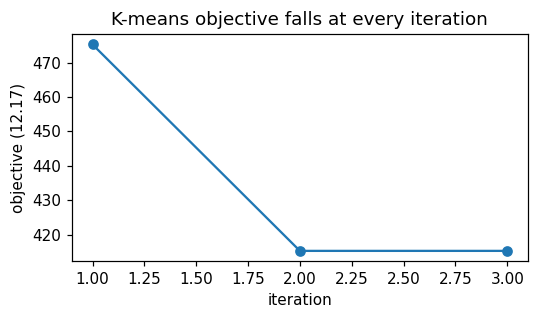

In [3]:
## ---- 1. Conceptual Q1: numerical checks of (12.18) and the K-means objective ---
# (a) numerical check of (12.18) on a random cluster; (b) the K-means objective at every half-step
rng = np.random.default_rng(1)
C = rng.normal(size=(25, 4))
lhs = sum(((C[i] - C[j]) ** 2).sum() for i in range(len(C)) for j in range(len(C))) / len(C)
rhs = 2 * ((C - C.mean(0)) ** 2).sum()
print(f"(12.18) left side {lhs:.6f}  right side {rhs:.6f}  difference {abs(lhs - rhs):.2e}")

X0 = np.vstack([rng.normal(m, 1, size=(40, 2)) for m in ((0, 0), (5, 5), (0, 6))])
K = 3; lab = rng.integers(0, K, len(X0)); obj = []
def objective(X, lab):     # (12.17): sum over clusters of (1/|Ck|) * sum of all pairwise squared distances
    return sum(((X[lab == k][:, None, :] - X[lab == k][None, :, :]) ** 2).sum() / max((lab == k).sum(), 1) for k in range(K))
for it in range(10):
    cent = np.array([X0[lab == k].mean(0) for k in range(K)])
    new = ((X0[:, None, :] - cent[None]) ** 2).sum(2).argmin(1)
    obj.append(objective(X0, new))
    if (new == lab).all():
        break
    lab = new
print("objective (12.17) after each iteration:", [round(o, 2) for o in obj])
print("never increases:", all(b <= a + 1e-9 for a, b in zip(obj, obj[1:])))
plt.figure(figsize=(5, 3)); plt.plot(range(1, len(obj) + 1), obj, "o-"); plt.xlabel("iteration"); plt.ylabel("objective (12.17)")
plt.title("K-means objective falls at every iteration"); save_fig("A7_fig_kmeans_check.png")
RESULTS["q1"] = {"lhs": lhs, "rhs": rhs, "objective_path": obj}

## Part 2. Applied Question 9 (ISLP Chapter 12): hierarchical clustering of USArrests
*Question (paraphrased; ISLP pp. 554–555):* (a) cluster the 50 states with complete linkage and Euclidean distance; (b) cut the dendrogram into three clusters and list the states in each; (c) repeat after scaling each variable to standard deviation one; (d) say what scaling changes and whether the variables should be scaled.

          count   mean   std   min    25%    50%    75%    max
Murder     50.0    7.8   4.4   0.8    4.1    7.2   11.2   17.4
Assault    50.0  170.8  83.3  45.0  109.0  159.0  249.0  337.0
UrbanPop   50.0   65.5  14.5  32.0   54.5   66.0   77.8   91.0
Rape       50.0   21.2   9.4   7.3   15.1   20.1   26.2   46.0

unscaled: cluster sizes {1: 16, 2: 14, 3: 20}
  cluster 1: Alabama, Alaska, Arizona, California, Delaware, Florida, Illinois, Louisiana, Maryland, Michigan, Mississippi, Nevada, New Mexico, New York, North Carolina, South Carolina
  cluster 2: Arkansas, Colorado, Georgia, Massachusetts, Missouri, New Jersey, Oklahoma, Oregon, Rhode Island, Tennessee, Texas, Virginia, Washington, Wyoming
  cluster 3: Connecticut, Hawaii, Idaho, Indiana, Iowa, Kansas, Kentucky, Maine, Minnesota, Montana, Nebraska, New Hampshire, North Dakota, Ohio, Pennsylvania, South Dakota, Utah, Vermont, West Virginia, Wisconsin
  cluster means:
   Murder  Assault  UrbanPop  Rape
1    11.8    272.6      68.3

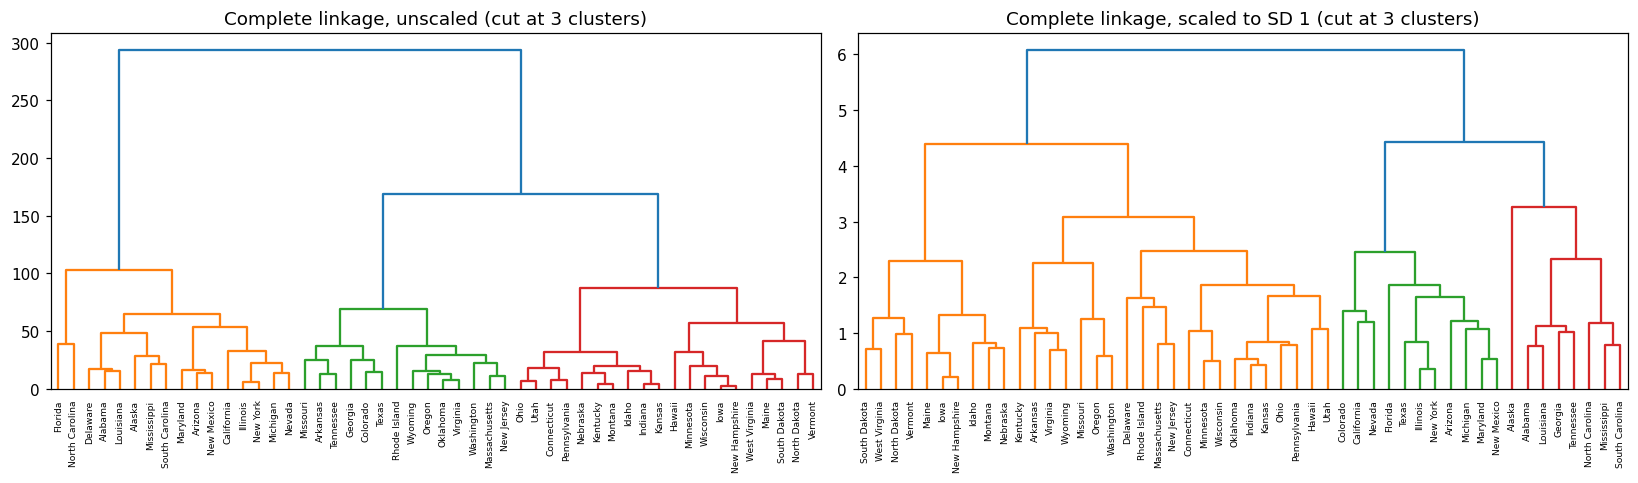

In [4]:
## ---- 2a. Applied Q9: USArrests, complete linkage, unscaled and scaled ----------
from ISLP import load_data
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram, cophenet
from scipy.spatial.distance import pdist
def load_usarrests():
    """USArrests ships with R; the ISLP labs load it with statsmodels' get_rdataset (needs internet, which Colab has)."""
    try:
        from statsmodels.datasets import get_rdataset
        return get_rdataset("USArrests").data
    except Exception:
        return pd.read_csv("https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/datasets/USArrests.csv", index_col=0)
usa = load_usarrests()
assert usa.shape == (50, 4), usa.shape
print(usa.describe().T.round(1))
Z_raw = linkage(usa.values, method="complete", metric="euclidean")                       # (a)
cl_raw = pd.Series(fcluster(Z_raw, 3, criterion="maxclust"), index=usa.index)            # (b)
usa_s = (usa - usa.mean()) / usa.std()
Z_sc = linkage(usa_s.values, method="complete", metric="euclidean")                       # (c)
cl_sc = pd.Series(fcluster(Z_sc, 3, criterion="maxclust"), index=usa.index)
for name, cl in (("unscaled", cl_raw), ("scaled", cl_sc)):
    print(f"\n{name}: cluster sizes {cl.value_counts().sort_index().to_dict()}")
    for k in sorted(cl.unique()):
        print(f"  cluster {k}: {', '.join(cl[cl == k].index)}")
    print("  cluster means:"); print(usa.groupby(cl).mean().round(1).to_string())
ct = pd.crosstab(cl_raw.rename("unscaled"), cl_sc.rename("scaled")); print("\nunscaled vs scaled:"); print(ct)
from sklearn.metrics import adjusted_rand_score
ari_us = adjusted_rand_score(cl_raw, cl_sc)
print(f"adjusted Rand index, unscaled vs scaled: {ari_us:.3f}")
print("SD of each variable:", usa.std().round(1).to_dict())
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
dendrogram(Z_raw, labels=list(usa.index), ax=ax[0], leaf_font_size=6, color_threshold=Z_raw[-2, 2])
ax[0].set_title("Complete linkage, unscaled (cut at 3 clusters)")
dendrogram(Z_sc, labels=list(usa.index), ax=ax[1], leaf_font_size=6, color_threshold=Z_sc[-2, 2])
ax[1].set_title("Complete linkage, scaled to SD 1 (cut at 3 clusters)")
save_fig("A7_fig_usarrests.png")
RESULTS["q9"] = {"unscaled": {str(k): list(cl_raw[cl_raw == k].index) for k in sorted(cl_raw.unique())},
                 "scaled": {str(k): list(cl_sc[cl_sc == k].index) for k in sorted(cl_sc.unique())},
                 "sizes_unscaled": cl_raw.value_counts().sort_index().to_dict(), "sizes_scaled": cl_sc.value_counts().sort_index().to_dict(),
                 "ari": ari_us, "sd": usa.std().to_dict(),
                 "means_unscaled": usa.groupby(cl_raw).mean().round(1).to_dict(), "means_scaled": usa.groupby(cl_sc).mean().round(1).to_dict()}

In [5]:
## ---- 2b. Applied Q9 (d): reading -----------------------------------------------
# ---- (d) Plain-language reading of Q9 (generated from the numbers above) ----
sd = usa.std()
print(f"* (a)-(b) Unscaled, the three clusters have sizes {cl_raw.value_counts().sort_index().tolist()}; they are ordered almost "
      f"entirely by Assault, whose SD ({sd['Assault']:.0f}) is {sd['Assault'] / sd.drop('Assault').max():.0f} times the next largest "
      f"({sd.drop('Assault').idxmax()}, {sd.drop('Assault').max():.1f}).")
print(f"* (c) Scaled, the sizes are {cl_sc.value_counts().sort_index().tolist()}, and UrbanPop and Rape now shape the groups as well.")
print(f"* (d) The two solutions agree only partly (adjusted Rand index {ari_us:.2f}). The variables should be scaled: they are in "
      "different units (arrests per 100,000 vs. percent urban), so without scaling the one with the largest numbers decides the "
      "distances, which reflects measurement units rather than anything about the states.")

* (a)-(b) Unscaled, the three clusters have sizes [16, 14, 20]; they are ordered almost entirely by Assault, whose SD (83) is 6 times the next largest (UrbanPop, 14.5).
* (c) Scaled, the sizes are [31, 11, 8], and UrbanPop and Rape now shape the groups as well.
* (d) The two solutions agree only partly (adjusted Rand index 0.37). The variables should be scaled: they are in different units (arrests per 100,000 vs. percent urban), so without scaling the one with the largest numbers decides the distances, which reflects measurement units rather than anything about the states.


## Part 3. Wine data: principal components analysis (PCA)
The data are 178 wines with 13 chemical measurements and no label. **Where the data come from:** the UCI Wine data (Aeberhard & Forina, 1991): wines grown in one region of Italy from three cultivars, measured by laboratory chemical tests only. The cultivar label has been removed in this Kaggle version, so nothing here can be checked against the true grape variety, and results may not carry over to wines from other regions or to sensory qualities. The measurements are on very different scales (proline in the hundreds, hue near 1), so they are standardized first; otherwise PCA would simply pick the variables with the largest numbers. PCA then replaces the 13 correlated measurements with uncorrelated components, and the smallest number of components that keeps at least 80% of the total variance is used for clustering. The 80% cut-off is the assignment's rule and a common convention, not a statistical test, so two data-driven checks are printed next to it: the Kaiser rule (eigenvalue above 1) and Horn's parallel analysis (keep a component only if its eigenvalue beats the 95th percentile of eigenvalues from random data of the same size).

**PCA assumption checks** (cell below): enough correlation to be worth reducing (Bartlett's test of sphericity and the Kaiser-Meyer-Olkin measure), linear relationships (PCA only captures linear structure), and outliers, which can pull components toward themselves.

file: wine-clustering.csv  shape: (178, 13)
columns: ['Alcohol', 'Malic_Acid', 'Ash', 'Ash_Alcanity', 'Magnesium', 'Total_Phenols', 'Flavanoids', 'Nonflavanoid_Phenols', 'Proanthocyanins', 'Color_Intensity', 'Hue', 'OD280', 'Proline']
Run started (UTC): 2026-11-04 15:55
SHA-256 wine-clustering.csv          4223d6f41e605264ffe91dfd907cb0c496c7c49d75db7f9e4251cc8e666e95a9
missing values: 0; duplicate rows: 0
                        mean     std     min      max
Alcohol                13.00    0.81   11.03    14.83
Malic_Acid              2.34    1.12    0.74     5.80
Ash                     2.37    0.27    1.36     3.23
Ash_Alcanity           19.49    3.34   10.60    30.00
Magnesium              99.74   14.28   70.00   162.00
Total_Phenols           2.30    0.63    0.98     3.88
Flavanoids              2.03    1.00    0.34     5.08
Nonflavanoid_Phenols    0.36    0.12    0.13     0.66
Proanthocyanins         1.59    0.57    0.41     3.58
Color_Intensity         5.06    2.32    1.28    13

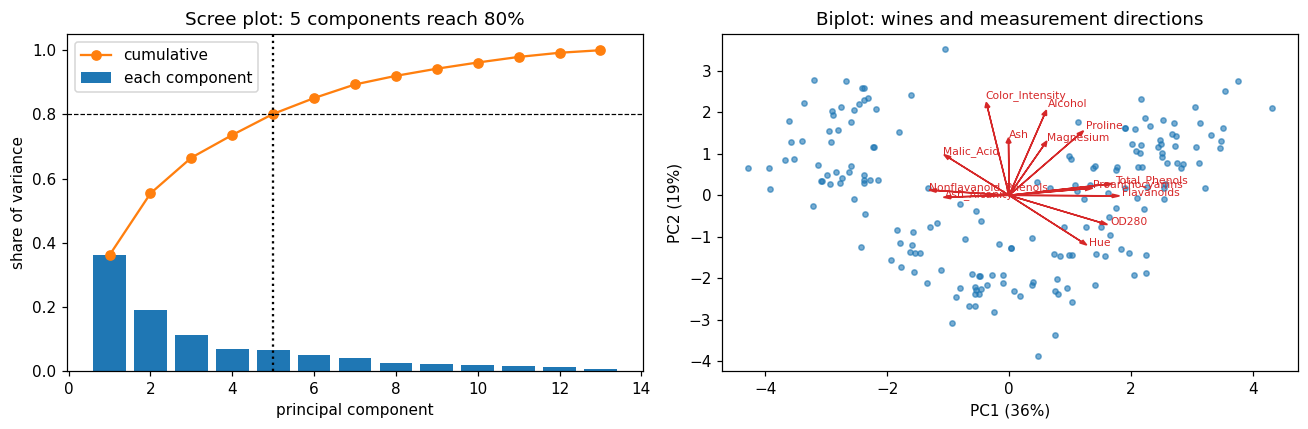

In [6]:
## ---- 3. Wine data: load, fingerprint, PCA assumption checks, PCA ---------------
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
unzip_all(DATA_DIR)
csvs = sorted(glob.glob(os.path.join(DATA_DIR, "*.csv")))
if not csvs and IN_COLAB:
    print("Choose the Kaggle wine zip (or the CSV):")
    for name, data in files.upload().items():
        open(os.path.join(DATA_DIR, name), "wb").write(data)
    unzip_all(DATA_DIR); csvs = sorted(glob.glob(os.path.join(DATA_DIR, "*.csv")))
assert csvs, f"No CSV found in {DATA_DIR}. Upload the Kaggle wine zip or CSV there."
wine = pd.read_csv(csvs[0])
wine = wine.loc[:, [c for c in wine.columns if not c.lower().startswith(("unnamed", "customer_segment", "class", "cultivar"))]]
print("file:", os.path.basename(csvs[0]), " shape:", wine.shape); print("columns:", list(wine.columns))
assert wine.shape[1] == 13 and len(wine) >= 150, "Expected 178 rows x 13 measurements"
FP = fingerprint([os.path.basename(csvs[0])])
print(f"missing values: {int(wine.isna().sum().sum())}; duplicate rows: {int(wine.duplicated().sum())}")
print(wine.describe().T[["mean", "std", "min", "max"]].round(2))

Zw = StandardScaler().fit_transform(wine)
# --- assumption checks for PCA ---
R = np.corrcoef(Zw, rowvar=False); n, p = Zw.shape
bart_chi2 = -(n - 1 - (2 * p + 5) / 6) * np.log(np.linalg.det(R)); bart_df = p * (p - 1) / 2
bart_p = stats.chi2.sf(bart_chi2, bart_df)
Rinv = np.linalg.inv(R); partial = -Rinv / np.sqrt(np.outer(np.diag(Rinv), np.diag(Rinv)))
off = ~np.eye(p, dtype=bool); kmo = (R[off] ** 2).sum() / ((R[off] ** 2).sum() + (partial[off] ** 2).sum())
abs_r = np.abs(R[off]); print(f"\nBartlett's sphericity: chi2 = {bart_chi2:.1f}, df = {bart_df:.0f}, p = {bart_p:.1e};  KMO = {kmo:.2f}")
print(f"|correlations| between measurements: median {np.median(abs_r):.2f}, max {abs_r.max():.2f}")
skew = wine.skew().round(2); print("skewness:", skew.to_dict())
z_out = (np.abs(Zw) > 3).any(1); print(f"wines with any |z| > 3: {int(z_out.sum())}")

pca = PCA().fit(Zw)
evr = pca.explained_variance_ratio_; cum = evr.cumsum()
n80 = int(np.argmax(cum >= 0.80) + 1)
print(f"\nvariance explained by each component: {np.round(evr, 3).tolist()}")
print(f"cumulative: {np.round(cum, 3).tolist()}")
print(f"components needed for 80%: {n80} (cumulative {cum[n80 - 1]:.3f}); eigenvalues > 1 (Kaiser): {int((pca.explained_variance_ > 1).sum())}")
# Horn's parallel analysis: eigenvalues of the real correlation matrix vs the 95th percentile from 500 random data sets of the same size
eig = np.sort(np.linalg.eigvalsh(R))[::-1]
rng_pa = np.random.default_rng(42)
rand_eig = np.array([np.sort(np.linalg.eigvalsh(np.corrcoef(rng_pa.normal(size=(n, p)), rowvar=False)))[::-1] for _ in range(500)])
pa95 = np.percentile(rand_eig, 95, axis=0)
above = eig > pa95
n_pa = int(p if above.all() else np.argmin(above))          # leading components that beat chance
print(f"parallel analysis (500 random data sets, 95th percentile): {n_pa} components beat chance")
print("  eigenvalue vs random 95th percentile, first 6:", [(round(float(a), 2), round(float(b), 2)) for a, b in zip(eig[:6], pa95[:6])])
print(f"  cumulative variance at {n_pa} (parallel analysis), {n80} (80% rule) components: {cum[n_pa - 1]:.3f}, {cum[n80 - 1]:.3f}")
load = pd.DataFrame(pca.components_[:n80].T, index=wine.columns, columns=[f"PC{i+1}" for i in range(n80)])
print("\nLoadings (correlation-scale weights) for the kept components:"); print(load.round(2))
scores = pca.transform(Zw)[:, :n80]
# PCA without outliers: do the components change much?
pca_wo = PCA(n_components=n80).fit(Zw[~z_out])
sim = [abs(np.dot(pca.components_[i], pca_wo.components_[i])) for i in range(n80)]
print("cosine similarity of each kept component with/without the |z|>3 wines:", np.round(sim, 3).tolist())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(range(1, p + 1), evr, label="each component"); ax[0].plot(range(1, p + 1), cum, "o-", c="C1", label="cumulative")
ax[0].axhline(.8, ls="--", c="k", lw=.8); ax[0].axvline(n80, ls=":", c="k"); ax[0].set_xlabel("principal component"); ax[0].set_ylabel("share of variance")
ax[0].set_title(f"Scree plot: {n80} components reach 80%"); ax[0].legend()
ax[1].scatter(scores[:, 0], scores[:, 1], s=12, alpha=.6)
for v, (a, b) in zip(wine.columns, pca.components_[:2].T):
    ax[1].arrow(0, 0, a * 4, b * 4, color="C3", head_width=.08); ax[1].text(a * 4.4, b * 4.4, v, fontsize=7, color="C3")
ax[1].set_xlabel(f"PC1 ({evr[0]:.0%})"); ax[1].set_ylabel(f"PC2 ({evr[1]:.0%})"); ax[1].set_title("Biplot: wines and measurement directions")
save_fig("A7_fig_pca.png")
top = {c: load[c].abs().sort_values(ascending=False).head(3).index.tolist() for c in load.columns}
RESULTS["data"] = {"n": int(n), "p": int(p), "missing": int(wine.isna().sum().sum()), "duplicates": int(wine.duplicated().sum()),
                   "columns": list(wine.columns), "sha256": FP, "outliers_z3": int(z_out.sum()), "skew": skew.to_dict()}
RESULTS["pca"] = {"evr": evr, "cum": cum, "n80": n80, "cum_n80": cum[n80 - 1], "kaiser": int((pca.explained_variance_ > 1).sum()),
                  "bartlett": {"chi2": bart_chi2, "df": bart_df, "p": bart_p}, "kmo": kmo, "median_abs_r": float(np.median(abs_r)),
                  "max_abs_r": float(abs_r.max()), "top_loadings": top, "loadings": load.round(3).to_dict(), "outlier_similarity": sim,
                  "parallel": {"n": n_pa, "eig": eig[:6].round(4), "pa95": pa95[:6].round(4), "cum_at_n": float(cum[n_pa - 1])}}

## Part 4. K-means on the principal-component scores, k = 2 to 8
K-means is run on the PC scores that keep at least 80% of the variance, with 50 random starts for each k (the algorithm only finds a local optimum, Part 1b). Four measures guide the choice of k:
* **Elbow:** within-cluster sum of squares; look for where adding a cluster stops paying off.
* **Silhouette** (higher is better, −1 to 1): how much closer each wine is to its own cluster than to the next one.
* **Calinski-Harabasz** (higher is better): between-cluster spread relative to within-cluster spread.
* **Davies-Bouldin** (lower is better): average similarity of each cluster to its most similar neighbour.

The final k is the one with the best silhouette. The other three measures are checks. To show how firm the choice is, k is chosen again by silhouette on 100 random subsamples of 80% of the wines; the share of subsamples that pick each k works like an error bar on the choice.

    inertia  silhouette  calinski_harabasz  davies_bouldin
2  1201.158       0.324             95.798           1.275
3   825.021       0.369            109.233           1.093
4   723.936       0.326             90.615           1.419
5   657.540       0.313             78.761           1.296
6   600.894       0.294             71.793           1.311
7   556.752       0.236             66.455           1.426
8   507.837       0.231             64.422           1.330
2                           [91, 87]
3                       [65, 51, 62]
4                   [52, 49, 33, 44]
5               [26, 24, 53, 50, 25]
6           [47, 13, 20, 47, 20, 31]
7       [27, 43, 15, 28, 19, 26, 20]
8    [20, 20, 22, 23, 5, 30, 22, 36]
Name: sizes, dtype: object
best k by each index: {'silhouette': 3, 'calinski_harabasz': 3, 'davies_bouldin': 3}
stability: adjusted Rand index of 20 single-start runs vs. the final solution: min 0.882, median 0.965
silhouette margin: k = 3 (0.369) vs runner-up k = 4 (0

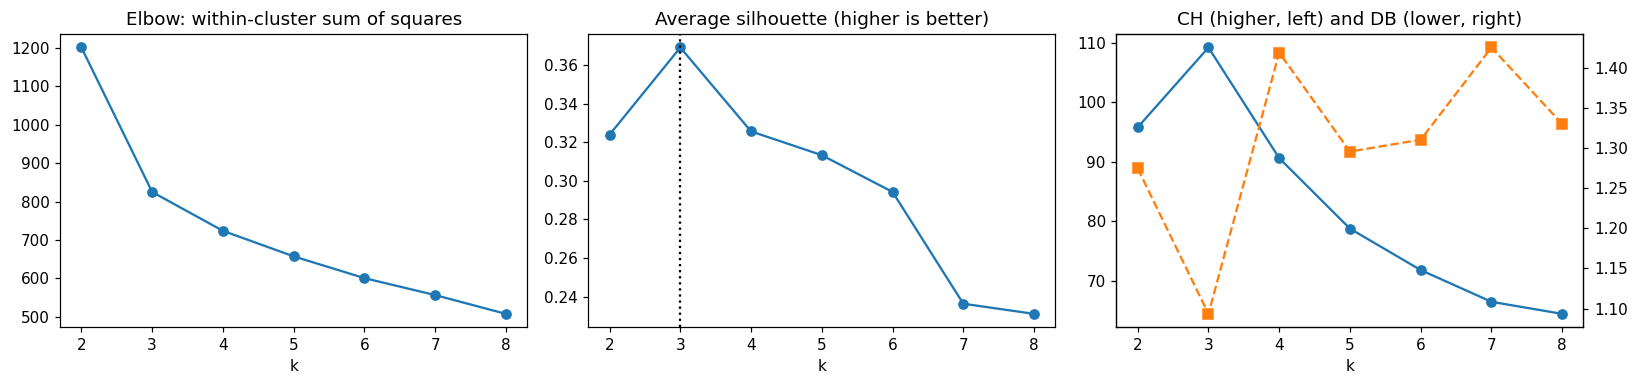

In [7]:
## ---- 4. k-means for k = 2 to 8 -------------------------------------------------
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, silhouette_samples
ks = range(2, 9); kres = {}
for k in ks:
    km = KMeans(n_clusters=k, n_init=50, random_state=42).fit(scores)
    kres[k] = {"inertia": km.inertia_, "silhouette": silhouette_score(scores, km.labels_),
               "calinski_harabasz": calinski_harabasz_score(scores, km.labels_), "davies_bouldin": davies_bouldin_score(scores, km.labels_),
               "sizes": np.bincount(km.labels_).tolist()}
ktab = pd.DataFrame(kres).T; print(ktab.drop(columns="sizes").astype(float).round(3)); print(ktab["sizes"])
k_best = int(ktab["silhouette"].astype(float).idxmax())
agree = {"silhouette": k_best, "calinski_harabasz": int(ktab["calinski_harabasz"].astype(float).idxmax()),
         "davies_bouldin": int(ktab["davies_bouldin"].astype(float).idxmin())}
print("best k by each index:", agree)
km = KMeans(n_clusters=k_best, n_init=50, random_state=42).fit(scores); lab_km = km.labels_
# stability across random starts
from sklearn.metrics import adjusted_rand_score
aris = [adjusted_rand_score(lab_km, KMeans(n_clusters=k_best, n_init=1, random_state=s).fit(scores).labels_) for s in range(20)]
print(f"stability: adjusted Rand index of 20 single-start runs vs. the final solution: min {min(aris):.3f}, median {np.median(aris):.3f}")
# how firmly do the data choose k? re-pick k by silhouette on 100 random 80% subsamples of the wines
sil_sorted = ktab["silhouette"].astype(float).sort_values(ascending=False)
print(f"silhouette margin: k = {sil_sorted.index[0]} ({sil_sorted.iloc[0]:.3f}) vs runner-up k = {sil_sorted.index[1]} ({sil_sorted.iloc[1]:.3f})")
rng_k = np.random.default_rng(42); k_votes = []
for b in range(100):
    sub = rng_k.choice(len(scores), int(.8 * len(scores)), replace=False)
    sil_b = {k: silhouette_score(scores[sub], KMeans(n_clusters=k, n_init=10, random_state=b).fit(scores[sub]).labels_) for k in ks}
    k_votes.append(max(sil_b, key=sil_b.get))
k_share = pd.Series(k_votes).value_counts(normalize=True).sort_index()
print("share of 100 subsamples (80% of wines) in which each k has the best silhouette:", k_share.round(2).to_dict())
# profile the clusters in original units
prof = wine.groupby(lab_km).mean().T; prof.columns = [f"cluster {c+1}" for c in prof.columns]
print("\nCluster means in original units:"); print(prof.round(2))
zprof = pd.DataFrame(Zw, columns=wine.columns).groupby(lab_km).mean().T
dist = {f"cluster {c+1}": zprof[c].sort_values(key=abs, ascending=False).head(3).round(2).to_dict() for c in zprof.columns}
print("most distinctive measurements (standardized means):", dist)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(list(ks), ktab["inertia"].astype(float), "o-"); ax[0].set_title("Elbow: within-cluster sum of squares"); ax[0].set_xlabel("k")
ax[1].plot(list(ks), ktab["silhouette"].astype(float), "o-"); ax[1].axvline(k_best, ls=":", c="k"); ax[1].set_title("Average silhouette (higher is better)"); ax[1].set_xlabel("k")
ax[2].plot(list(ks), ktab["calinski_harabasz"].astype(float), "o-", label="Calinski-Harabasz")
a2 = ax[2].twinx(); a2.plot(list(ks), ktab["davies_bouldin"].astype(float), "s--", c="C1", label="Davies-Bouldin")
ax[2].set_title("CH (higher, left) and DB (lower, right)"); ax[2].set_xlabel("k")
save_fig("A7_fig_kchoice.png")
RESULTS["kmeans"] = {"table": {str(k): {kk: (vv if kk == "sizes" else float(vv)) for kk, vv in v.items()} for k, v in kres.items()},
                     "k_best": k_best, "best_by_index": agree, "stability_min": min(aris), "stability_median": float(np.median(aris)),
                     "sil_runner_up": {"k": int(sil_sorted.index[1]), "silhouette": float(sil_sorted.iloc[1])},
                     "k_subsample_share": {str(k): float(v) for k, v in k_share.items()},
                     "profile": prof.round(2).to_dict(), "distinctive": dist}

## Part 5. Hierarchical clustering
Agglomerative clustering on the same PC scores, with Euclidean distance. Ward linkage (merge the pair of clusters that adds the least within-cluster variance, the same criterion as k-means) is the main method; complete and average linkage are shown for comparison. The cophenetic correlation measures how faithfully each dendrogram preserves the original distances. Each tree is cut at the k chosen in Part 4 and compared with k-means using the adjusted Rand index (1 = identical groupings, 0 = chance agreement).

         cophenetic ari_vs_kmeans silhouette          sizes
ward       0.691051      0.826576   0.346793   [55, 65, 58]
complete   0.543319      0.480868   0.227603  [23, 48, 107]
average    0.769069      0.494667   0.317735   [50, 127, 1]

Ward clusters vs k-means clusters:
k-means   0   1   2
Ward               
0         6  49   0
1         3   0  62
2        56   2   0
largest Ward merge heights (last 8): [34.6, 28.0, 12.8, 12.5, 11.6, 9.7, 8.9, 8.6]


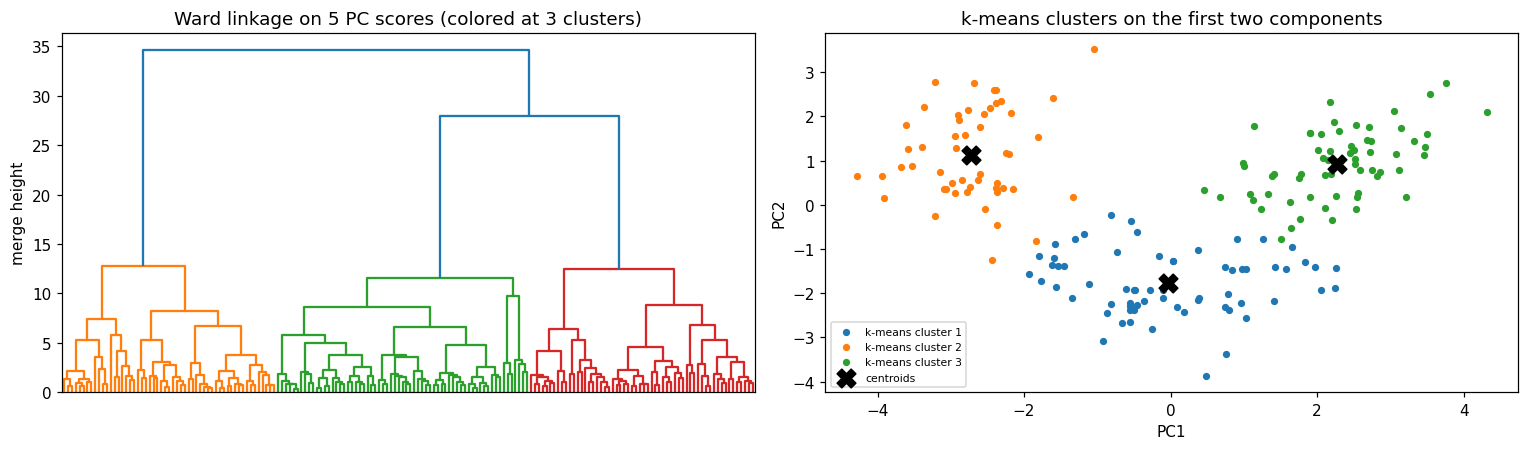

In [8]:
## ---- 5. Hierarchical clustering (Ward, complete, average) ----------------------
Dpc = pdist(scores)
hres, links = {}, {}
for meth in ("ward", "complete", "average"):
    Zl = linkage(scores, method=meth); links[meth] = Zl
    lab_h = fcluster(Zl, k_best, criterion="maxclust") - 1
    hres[meth] = {"cophenetic": float(cophenet(Zl, Dpc)[0]), "ari_vs_kmeans": adjusted_rand_score(lab_km, lab_h),
                  "silhouette": silhouette_score(scores, lab_h) if len(set(lab_h)) > 1 else float("nan"),
                  "sizes": np.bincount(lab_h).tolist()}
htab = pd.DataFrame(hres).T; print(htab)
lab_w = fcluster(links["ward"], k_best, criterion="maxclust") - 1
print("\nWard clusters vs k-means clusters:"); print(pd.crosstab(pd.Series(lab_w, name="Ward"), pd.Series(lab_km, name="k-means")))
gaps = np.diff(links["ward"][-8:, 2])[::-1]
print("largest Ward merge heights (last 8):", np.round(links["ward"][-8:, 2][::-1], 1).tolist())

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
dendrogram(links["ward"], ax=ax[0], no_labels=True, color_threshold=links["ward"][-(k_best - 1), 2])
ax[0].set_title(f"Ward linkage on {n80} PC scores (colored at {k_best} clusters)"); ax[0].set_ylabel("merge height")
for c in range(k_best):
    ax[1].scatter(scores[lab_km == c, 0], scores[lab_km == c, 1], s=14, label=f"k-means cluster {c+1}")
ax[1].scatter(*km.cluster_centers_[:, :2].T, marker="X", s=150, c="k", label="centroids")
ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2"); ax[1].legend(fontsize=7); ax[1].set_title("k-means clusters on the first two components")
save_fig("A7_fig_dendrogram.png")
RESULTS["hier"] = {"table": hres, "ward_vs_kmeans": pd.crosstab(lab_w, lab_km).values.tolist()}

## Part 6. Clustering assumption checks
K-means assumes clusters that are roughly spherical, of similar spread, and well separated, on standardized inputs. These are checked with per-cluster silhouettes (any cluster with many negative values is poorly separated), the spread of each cluster along each kept component, and cluster sizes. Hierarchical clustering assumes the chosen distance and linkage suit the data, checked by the cophenetic correlations above. A final check reruns k-means on all 13 standardized measurements (no PCA), and on only the components kept by parallel analysis, to see whether the number of components kept changes the groups.

In [9]:
## ---- 6. Clustering assumption checks -------------------------------------------
sil = silhouette_samples(scores, lab_km)
sil_by = {f"cluster {c+1}": {"mean": float(sil[lab_km == c].mean()), "share_negative": float((sil[lab_km == c] < 0).mean()),
                             "size": int((lab_km == c).sum())} for c in range(k_best)}
print("per-cluster silhouette:", {k: {kk: round(vv, 3) for kk, vv in v.items()} for k, v in sil_by.items()})
spread = pd.DataFrame({f"cluster {c+1}": scores[lab_km == c].std(0) for c in range(k_best)}, index=[f"PC{i+1}" for i in range(n80)])
print("\nSD of each cluster along each component (similar values = roughly spherical, equal-spread clusters):"); print(spread.round(2))
ratio = float(spread.values.max() / spread.values.min())
km_full = KMeans(n_clusters=k_best, n_init=50, random_state=42).fit(Zw)
ari_full = adjusted_rand_score(lab_km, km_full.labels_)
print(f"\nlargest/smallest spread ratio: {ratio:.2f};  k-means on all 13 standardized measurements vs on {n80} PCs: ARI {ari_full:.3f}")
n_pa = RESULTS["pca"]["parallel"]["n"]
ari_pa = adjusted_rand_score(lab_km, KMeans(n_clusters=k_best, n_init=50, random_state=42).fit(scores[:, :n_pa]).labels_)
print(f"k-means on the {n_pa} components kept by parallel analysis vs on {n80} PCs: ARI {ari_pa:.3f}")
RESULTS["checks"] = {"silhouette_by_cluster": sil_by, "spread": spread.round(3).to_dict(), "spread_ratio": ratio, "ari_full_vs_pca": ari_full,
                     "ari_parallel_vs_n80": ari_pa}

per-cluster silhouette: {'cluster 1': {'mean': 0.246, 'share_negative': 0.077, 'size': 65}, 'cluster 2': {'mean': 0.461, 'share_negative': 0.0, 'size': 51}, 'cluster 3': {'mean': 0.423, 'share_negative': 0.0, 'size': 62}}

SD of each cluster along each component (similar values = roughly spherical, equal-spread clusters):
     cluster 1  cluster 2  cluster 3
PC1       1.11       0.64       0.79
PC2       0.71       1.02       0.76
PC3       1.30       0.92       1.27
PC4       1.23       0.71       0.78
PC5       0.99       0.94       0.82

largest/smallest spread ratio: 2.05;  k-means on all 13 standardized measurements vs on 5 PCs: ARI 1.000
k-means on the 3 components kept by parallel analysis vs on 5 PCs: ARI 0.982


In [10]:
## ---- 7. Plain-language reading of Parts 3-6 ------------------------------------
# ---- Plain-language reading (generated from the numbers above) ----
P = RESULTS["pca"]; Kk = RESULTS["kmeans"]; H = RESULTS["hier"]["table"]
print(f"* PCA is worthwhile: Bartlett's test rejects 'no correlation' (p = {P['bartlett']['p']:.1e}) and KMO = {P['kmo']:.2f}. "
      f"{P['n80']} components keep {P['cum_n80']:.0%} of the variance (PC1 alone {P['evr'][0]:.0%}).")
print(f"* The 80% rule keeps {P['n80']} components; parallel analysis keeps {P['parallel']['n']} (the components beyond that add variance "
      f"that random data of this size would also show), and the Kaiser rule keeps {P['kaiser']}.")
print(f"* PC1 is driven by {', '.join(P['top_loadings']['PC1'])}; PC2 by {', '.join(P['top_loadings']['PC2'])}.")
print(f"* k-means: silhouette is highest at k = {Kk['k_best']} ({Kk['table'][str(Kk['k_best'])]['silhouette']:.2f}); "
      f"Calinski-Harabasz picks {Kk['best_by_index']['calinski_harabasz']} and Davies-Bouldin picks {Kk['best_by_index']['davies_bouldin']}. "
      f"The solution is stable (median ARI across single starts {Kk['stability_median']:.2f}).")
_ks = Kk['k_subsample_share'].get(str(Kk['k_best']), 0)
print(f"* The choice of k is {'firm' if _ks >= .8 else 'fairly firm' if _ks >= .6 else 'not firm'}: k = {Kk['k_best']} wins in {_ks:.0%} of 100 random 80% subsamples "
      f"(silhouette {Kk['table'][str(Kk['k_best'])]['silhouette']:.3f} vs {Kk['sil_runner_up']['silhouette']:.3f} for k = {Kk['sil_runner_up']['k']}).")
print(f"* Hierarchical: Ward agrees with k-means at ARI {H['ward']['ari_vs_kmeans']:.2f}; complete {H['complete']['ari_vs_kmeans']:.2f}, average {H['average']['ari_vs_kmeans']:.2f}. "
      f"Cophenetic correlations: Ward {H['ward']['cophenetic']:.2f}, complete {H['complete']['cophenetic']:.2f}, average {H['average']['cophenetic']:.2f}.")
print(f"* Clustering on all 13 measurements instead of {P['n80']} components gives nearly the same groups (ARI {RESULTS['checks']['ari_full_vs_pca']:.2f}), "
      f"so dropping {1 - P['cum_n80']:.0%} of the variance lost little cluster structure. Using only the {P['parallel']['n']} components kept by parallel analysis "
      f"gives ARI {RESULTS['checks']['ari_parallel_vs_n80']:.2f} against the {P['n80']}-component solution.")

* PCA is worthwhile: Bartlett's test rejects 'no correlation' (p = 2.5e-224) and KMO = 0.78. 5 components keep 80% of the variance (PC1 alone 36%).
* The 80% rule keeps 5 components; parallel analysis keeps 3 (the components beyond that add variance that random data of this size would also show), and the Kaiser rule keeps 3.
* PC1 is driven by Flavanoids, Total_Phenols, OD280; PC2 by Color_Intensity, Alcohol, Proline.
* k-means: silhouette is highest at k = 3 (0.37); Calinski-Harabasz picks 3 and Davies-Bouldin picks 3. The solution is stable (median ARI across single starts 0.97).
* The choice of k is firm: k = 3 wins in 99% of 100 random 80% subsamples (silhouette 0.369 vs 0.326 for k = 4).
* Hierarchical: Ward agrees with k-means at ARI 0.83; complete 0.48, average 0.49. Cophenetic correlations: Ward 0.69, complete 0.54, average 0.77.
* Clustering on all 13 measurements instead of 5 components gives nearly the same groups (ARI 1.00), so dropping 20% of the variance lost little clust

In [11]:
## ---- 8. Environment report and results JSON ------------------------------------
RESULTS_FILE = "A7_results.json"
# ---- Environment report (the Python equivalent of R's sessionInfo()) ----
import importlib, platform
VERSIONS = {"python": platform.python_version()}
for pkg in ("numpy", "pandas", "sklearn", "statsmodels", "scipy", "matplotlib", "ISLP"):
    try:
        VERSIONS[pkg] = importlib.import_module(pkg).__version__
    except Exception:
        VERSIONS[pkg] = "not installed"
print("Environment:", VERSIONS)
print(f"Total run time: {(time.time() - T0) / 60:.1f} min")
RESULTS["environment"] = VERSIONS

# ---- Results used in the paper (printed so they are saved in the notebook) ----
def _clean(o):
    if isinstance(o, dict):
        return {str(k): _clean(v) for k, v in o.items() if not str(k).startswith("_")}
    if isinstance(o, (list, tuple)):
        return [_clean(v) for v in o]
    if isinstance(o, np.ndarray):
        return _clean(o.tolist())
    if isinstance(o, (np.floating, np.integer, np.bool_)):
        return o.item()
    if isinstance(o, float) and o != o:
        return None
    return o
RESULTS = _clean(RESULTS)
with open(os.path.join(OUT_DIR, RESULTS_FILE), "w") as f:
    json.dump(RESULTS, f, indent=1)
print("RESULTS_JSON_START")
print(json.dumps(RESULTS))
print("RESULTS_JSON_END")

Environment: {'python': '3.13.18', 'numpy': '2.4.6', 'pandas': '2.2.3', 'sklearn': '1.6.1', 'statsmodels': '0.15.0', 'scipy': '1.16.3', 'matplotlib': '3.10.0', 'ISLP': '0.6.0'}
Total run time: 1.0 min
RESULTS_JSON_START
{"q1": {"lhs": 142.3878043115441, "rhs": 142.38780431154427, "objective_path": [475.2375578221395, 415.2969526937698, 415.2969526937698]}, "q9": {"unscaled": {"1": ["Alabama", "Alaska", "Arizona", "California", "Delaware", "Florida", "Illinois", "Louisiana", "Maryland", "Michigan", "Mississippi", "Nevada", "New Mexico", "New York", "North Carolina", "South Carolina"], "2": ["Arkansas", "Colorado", "Georgia", "Massachusetts", "Missouri", "New Jersey", "Oklahoma", "Oregon", "Rhode Island", "Tennessee", "Texas", "Virginia", "Washington", "Wyoming"], "3": ["Connecticut", "Hawaii", "Idaho", "Indiana", "Iowa", "Kansas", "Kentucky", "Maine", "Minnesota", "Montana", "Nebraska", "New Hampshire", "North Dakota", "Ohio", "Pennsylvania", "South Dakota", "Utah", "Vermont", "West Vir